In [4]:
# --- IMPORTS AND SETUP ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from mpl_toolkits.mplot3d import Axes3D
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, classification_report
import warnings

In [5]:
# 1. Основные библиотеки для работы с данными и визуализации
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D

# 2. Предобработка и снижение размерности
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split

# 3. Кластеризация (Unsupervised Learning)
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 4. Модели машинного обучения (Supervised Learning)
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor

# 5. Метрики качества
from sklearn.metrics import (
    mean_squared_error, 
    r2_score, 
    accuracy_score, 
    classification_report
)

# 6. Настройки
import warnings
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid') # Опционально: красивый стиль для графиков

In [6]:
# Настройки отображения Pandas
pd.set_option('display.float_format', lambda x: '%.2f' % x)  # 2 знака после запятой для денежных метрик
pd.set_option('display.max_rows', 100)                      # Чтобы случайно не подвесить ноутбук огромным выводом
pd.set_option('display.max_columns', None)                  # Показывать все столбцы
pd.set_option('display.width', None)                        # Авто-ширина
pd.set_option('display.max_colwidth', None)                 # Показываем текст полностью

# Игнорирование предупреждений
warnings.filterwarnings('ignore')

Read Dataset

df = pd.read_csv('shopping_behavior_updated.csv')
data = df.copy()
data.head()

Использую pip install kagglehub

In [8]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("ranaghulamnabi/shopping-behavior-and-preferences-study")

print("Path to dataset files:", path)

100%|██████████| 70.5k/70.5k [00:00<00:00, 300kB/s]

Extracting files...


Path to dataset files: C:\Users\Asus\.cache\kagglehub\datasets\ranaghulamnabi\shopping-behavior-and-preferences-study\versions\1


In [15]:
df = pd.read_csv('../data/Shopping Behavior/shopping_behavior_updated.csv')
data = df.copy()  # согласны стоит сохранить копию изначальных базы данных  
data.head()

,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Payment Method,Frequency of Purchases
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.10,Yes,Express,Yes,Yes,14,Venmo,Fortnightly
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.10,Yes,Express,Yes,Yes,2,Cash,Fortnightly
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.10,Yes,Free Shipping,Yes,Yes,23,Credit Card,Weekly
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.50,Yes,Next Day Air,Yes,Yes,49,PayPal,Weekly
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.70,Yes,Free Shipping,Yes,Yes,31,PayPal,Annually


Data Cleaning and Encoding

In [16]:
# Case Conversion and Whitespace Removal
categorical_cols = df.select_dtypes(include='object').columns
for col in categorical_cols:
    df[col] = df[col].astype(str).str.lower().str.strip()
df = df.drop('Customer ID', axis=1) 

In [ ]:
## Этот блок кода выполняет первичную стандартизацию текстовых данных и очистку от лишних идентификаторов:

categorical_cols = df.select_dtypes(include='object').columns — находит все столбцы с текстовым (категориальным) типом данных.

for col in categorical_cols: df[col] = df[col].astype(str).str.lower().str.strip() — проходит по каждому текстовому столбцу и:

приводит значения к строкам (.astype(str));

переводит весь текст в нижний регистр (.str.lower()), чтобы значения вроде 'Male' и 'male' не считались разными категориями;

удаляет случайные пробелы в начале и конце строк (.str.strip()).

df = df.drop('Customer ID', axis=1) — удаляет столбец с уникальным идентификатором клиента, 
так как уникальные ID не несут смысловой нагрузки для статистического анализа и моделей машинного обучения
(например, кластеризации K-Means).

Создаем mapping для будущего анализа

1. Binary Encoding (Gender, Subscription Status, Discount Applied, Promo Code Used)

In [18]:
df['Gender'] = df['Gender'].map({'male': 1, 'female': 0})
df['Subscription Status'] = df['Subscription Status'].map({'yes': 1, 'no': 0})
df['Discount Applied'] = df['Discount Applied'].map({'yes': 1, 'no': 0})
df['Promo Code Used'] = df['Promo Code Used'].map({'yes': 1, 'no': 0})

In [20]:
# 2. Ordinal Encoding ('Size' and 'Frequency of Purchases')
size_mapping = {'s': 0, 'm': 1, 'l': 2, 'xl': 3}
df['Size'] = df['Size'].map(size_mapping)

frequency_mapping = {
    'annually': 1, 'every 3 months': 4, 'quarterly': 4,
    'monthly': 12, 'fortnightly': 26, 'bi-weekly': 26, 'weekly': 52
}
df['Frequency of Purchases'] = df['Frequency of Purchases'].map(frequency_mapping)

Важно!

Если до этого был выполнен код .str.lower(), преобразование пройдет без ошибок.

Если в исходной колонке встретится значение, которого нет в словаре (например, 'xxl' или пропуск NaN),
 метод .map() подставит вместо него NaN (пустое значение).

In [21]:
# 3. One-Hot Encoding (Remaining Nominal Categorical Columns)
columns_for_one_hot_encoding = [
    'Category', 'Season', 'Shipping Type', 'Payment Method'#, 'Color'
]
df_encoded = pd.get_dummies(df, columns=columns_for_one_hot_encoding, drop_first=True)

In [22]:
# 4. Feature Creation 
bins = 3
labels = ['low', 'medium', 'high']
df_encoded['Purchase_Amount_Bins'] = pd.qcut(df_encoded['Purchase Amount (USD)'], q=bins, labels=labels)

age_bins = [0, 18, 25, 35, 45, 55, 65, 100]
age_labels = ['<18', '18-24', '25-34', '35-44', '45-54', '55-64', '65+']
df_encoded['Age_Group'] = pd.cut(df_encoded['Age'], bins=age_bins, labels=age_labels, right=False)

review_bins = [1, 3, 4, 5.1]
review_labels = ['negative', 'neutral', 'positive']
df_encoded['Review_Sentiment'] = pd.cut(df_encoded['Review Rating'], bins=review_bins, labels=review_labels, right=False)

print("Data Cleaning and Encoding Complete. Final DataFrame is df_encoded.")

Data Cleaning and Encoding Complete. Final DataFrame is df_encoded.


Exploratory Data Analysis (EDA)

--- DATA INSPECTION AND SUMMARY ---

In [24]:
print("--- Data Information ---")
df.info()

--- Data Information ---
<class 'pandas.DataFrame'>
RangeIndex: 3900 entries, 0 to 3899
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Age                     3900 non-null   int64  
 1   Gender                  3900 non-null   int64  
 2   Item Purchased          3900 non-null   str    
 3   Category                3900 non-null   str    
 4   Purchase Amount (USD)   3900 non-null   int64  
 5   Location                3900 non-null   str    
 6   Size                    3900 non-null   int64  
 7   Color                   3900 non-null   str    
 8   Season                  3900 non-null   str    
 9   Review Rating           3900 non-null   float64
 10  Subscription Status     3900 non-null   int64  
 11  Shipping Type           3900 non-null   str    
 12  Discount Applied        3900 non-null   int64  
 13  Promo Code Used         3900 non-null   int64  
 14  Previous Purchases      39

In [25]:
# Inspecting Unique Values Per Column
categorical_cols = df.select_dtypes(include='object').columns
unique_values_summary = pd.DataFrame({
    'Column': df.columns,
    'Unique Values Count': [df[col_name].nunique() for col_name in df.columns],
    'Unique Values': [df[col_name].unique() for col_name in df.columns]
})
print("\n--- Unique Values Summary ---")
display(unique_values_summary)


--- Unique Values Summary ---


,Column,Unique Values Count,Unique Values
0,Age,53,"[55, 19, 50, 21, 45, 46, 63, 27, 26, 57, 53, 30, 61, 65, 64, 25, 52, 66, 31, 56, 18, 38, 54, 33, 36, 35, 29, 70, 69, 67, 20, 39, 42, 68, 49, 59, 47, 40, 41, 48, 22, 24, 44, 37, 58, 32, 62, 51, 28, 43, 34, 23, 60]"
1,Gender,2,"[1, 0]"
2,Item Purchased,25,"[blouse, sweater, jeans, sandals, sneakers, shirt, shorts, coat, handbag, shoes, dress, skirt, sunglasses, pants, jacket, hoodie, jewelry, t-shirt, scarf, hat, socks, backpack, belt, boots, gloves]"
3,Category,4,"[clothing, footwear, outerwear, accessories]"
4,Purchase Amount (USD),81,"[53, 64, 73, 90, 49, 20, 85, 34, 97, 31, 68, 72, 51, 81, 36, 38, 48, 62, 37, 88, 22, 25, 56, 94, 79, 67, 91, 33, 69, 45, 60, 76, 39, 100, 21, 43, 54, 55, 30, 28, 59, 24, 83, 46, 70, 29, 26, 58, 96, 40, 32, 95, 41, 47, 99, 87, 92, 98, 89, 35, 75, 65, 86, 84, 77, 27, 23, 74, 80, 42, 61, 82, 78, 93, 50, 57, 66, 44, 52, 71, 63]"
5,Location,50,"[kentucky, maine, massachusetts, rhode island, oregon, wyoming, montana, louisiana, west virginia, missouri, arkansas, hawaii, delaware, new hampshire, new york, alabama, mississippi, north carolina, california, oklahoma, florida, texas, nevada, kansas, colorado, north dakota, illinois, indiana, arizona, alaska, tennessee, ohio, new jersey, maryland, vermont, new mexico, south carolina, idaho, pennsylvania, connecticut, utah, virginia, georgia, nebraska, iowa, south dakota, minnesota, washington, wisconsin, michigan]"
6,Size,4,"[2, 0, 1, 3]"
7,Color,25,"[gray, maroon, turquoise, white, charcoal, silver, pink, purple, olive, gold, violet, teal, lavender, black, green, peach, red, cyan, brown, beige, orange, indigo, yellow, magenta, blue]"
8,Season,4,"[winter, spring, summer, fall]"
9,Review Rating,26,"[3.1, 3.5, 2.7, 2.9, 3.2, 2.6, 4.8, 4.1, 4.9, 4.5, 4.7, 2.8, 4.6, 3.3, 4.4, 3.6, 5.0, 4.0, 3.7, 4.2, 3.9, 3.0, 3.8, 3.4, 4.3, 2.5]"


--- OUTLIER ANALYSIS AND DISTRIBUTION ---

In [26]:
# 1. Purchase Amount (USD)
print("\n--- 1. Purchase Amount (USD) Analysis ---")
plt.figure(figsize=(10, 4))


--- 1. Purchase Amount (USD) Analysis ---


<Figure size 1000x400 with 0 Axes>

<Figure size 1000x400 with 0 Axes>

Text(0.5, 1.0, 'Box Plot of Purchase Amount (USD)')

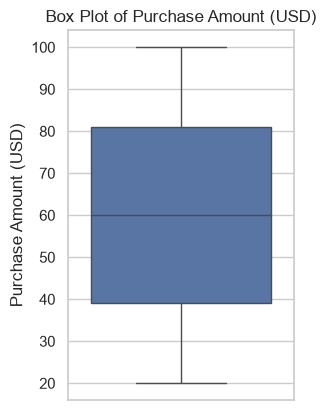

In [27]:
# Subplot 1: Box Plot
plt.subplot(1, 2, 1)
sns.boxplot(y=df['Purchase Amount (USD)'])
plt.title('Box Plot of Purchase Amount (USD)')

Text(0.5, 1.0, 'Density Plot of Purchase Amount (USD)')

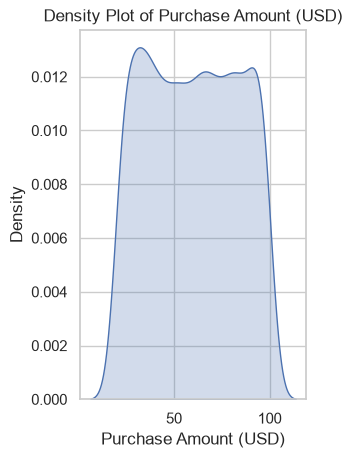

In [28]:
# Subplot 2: Density Plot
plt.subplot(1, 2, 2)
sns.kdeplot(df['Purchase Amount (USD)'], fill=True)
plt.title('Density Plot of Purchase Amount (USD)')

In [29]:
plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>

In [30]:
# IQR Outlier Check
Q1 = df['Purchase Amount (USD)'].quantile(0.25)
Q3 = df['Purchase Amount (USD)'].quantile(0.75)
IQR = Q3 - Q1
upper_bound = Q3 + 1.5 * IQR
outliers = df[(df['Purchase Amount (USD)'] > upper_bound)]
print(f"Descriptive Statistics:\n{df['Purchase Amount (USD)'].describe()}")
print(f"\nOutliers above 1.5*IQR ({upper_bound:.2f}): {len(outliers)}")

Descriptive Statistics:
count   3900.00
mean      59.76
std       23.69
min       20.00
25%       39.00
50%       60.00
75%       81.00
max      100.00
Name: Purchase Amount (USD), dtype: float64

Outliers above 1.5*IQR (144.00): 0


In [31]:
# 2. Previous Purchases
print("\n--- 2. Previous Purchases Analysis ---")
plt.figure(figsize=(10, 4))


--- 2. Previous Purchases Analysis ---


<Figure size 1000x400 with 0 Axes>

<Figure size 1000x400 with 0 Axes>

Text(0.5, 1.0, 'Box Plot of Previous Purchases')

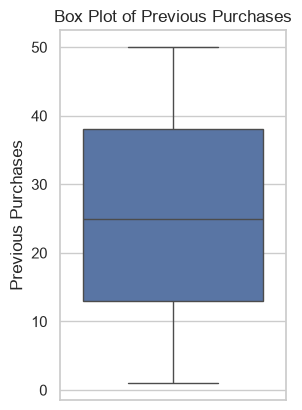

In [32]:
# Subplot 1: Box Plot
plt.subplot(1, 2, 1)
sns.boxplot(y=df['Previous Purchases'])
plt.title('Box Plot of Previous Purchases')

Text(0.5, 1.0, 'Density Plot of Previous Purchases')

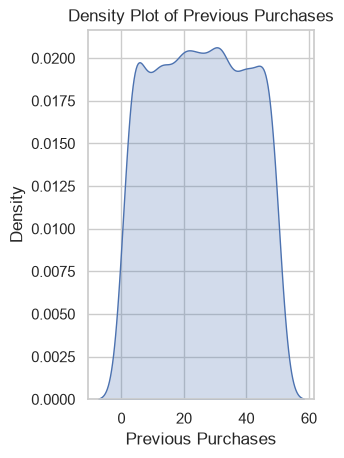

In [33]:
# Subplot 2: Density Plot
plt.subplot(1, 2, 2)
sns.kdeplot(df['Previous Purchases'], fill=True)
plt.title('Density Plot of Previous Purchases')

In [34]:
plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>

In [35]:
# IQR Outlier Check
Q3_prev = df['Previous Purchases'].quantile(0.75)
IQR_prev = Q3_prev - df['Previous Purchases'].quantile(0.25)
upper_bound_prev = Q3_prev + 1.5 * IQR_prev
outliers_prev = df[(df['Previous Purchases'] > upper_bound_prev)]
print(f"Descriptive Statistics:\n{df['Previous Purchases'].describe()}")
print(f"\nOutliers above 1.5*IQR ({upper_bound_prev:.2f}): {len(outliers_prev)}")

Descriptive Statistics:
count   3900.00
mean      25.35
std       14.45
min        1.00
25%       13.00
50%       25.00
75%       38.00
max       50.00
Name: Previous Purchases, dtype: float64

Outliers above 1.5*IQR (75.50): 0


 --- UNIVARIATE ANALYSIS (Review Rating and Age) ---


--- 3. Review Rating & Sentiment Analysis ---


Text(0.5, 1.0, 'Box Plot of Review Rating')

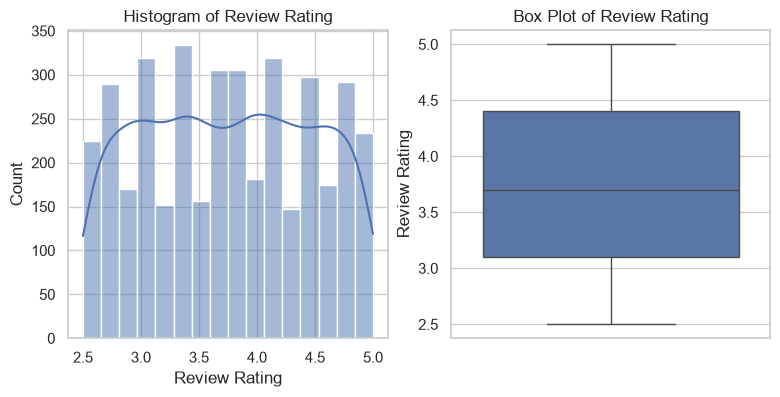

In [37]:
print("\n--- 3. Review Rating & Sentiment Analysis ---")
plt.figure(figsize=(14, 4))

# Subplot 1: Histogram for Review Rating
plt.subplot(1, 3, 1)
sns.histplot(df['Review Rating'], kde=True)
plt.title('Histogram of Review Rating')

# Subplot 2: Box Plot for Review Rating
plt.subplot(1, 3, 2)
sns.boxplot(y=df['Review Rating'])
plt.title('Box Plot of Review Rating')

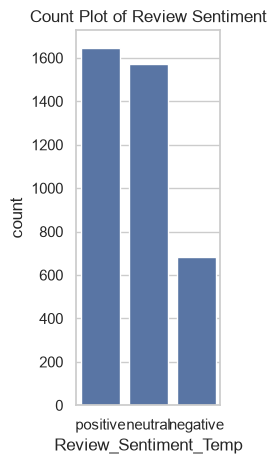

In [38]:
# Subplot 3: Count Plot of Review Sentiment 

review_bins = [1, 3, 4, 5.1]
review_labels = ['negative', 'neutral', 'positive']
df['Review_Sentiment_Temp'] = pd.cut(df['Review Rating'], bins=review_bins, labels=review_labels, right=False)
plt.subplot(1, 3, 3)
sns.countplot(x=df['Review_Sentiment_Temp'], order=df['Review_Sentiment_Temp'].value_counts().index)
plt.title('Count Plot of Review Sentiment')
df.drop('Review_Sentiment_Temp', axis=1, inplace=True) # Drop temp column

plt.tight_layout()
plt.show()

In [39]:
print("\n--- 4. Age and Age Group Analysis ---")
plt.figure(figsize=(14, 4))


--- 4. Age and Age Group Analysis ---


<Figure size 1400x400 with 0 Axes>

<Figure size 1400x400 with 0 Axes>

Text(0.5, 1.0, 'Histogram of Age')

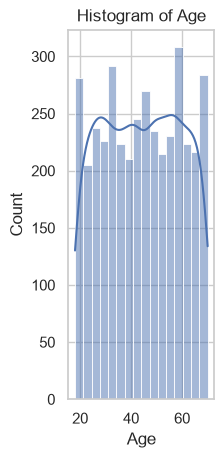

In [40]:
# Subplot 1: Histogram for Age
plt.subplot(1, 3, 1)
sns.histplot(df['Age'], kde=True)
plt.title('Histogram of Age')

Text(0.5, 1.0, 'Box Plot of Age')

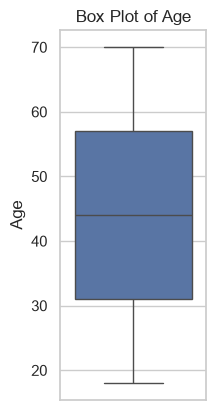

In [41]:
# Subplot 2: Box Plot for Age
plt.subplot(1, 3, 2)
sns.boxplot(y=df['Age'])
plt.title('Box Plot of Age')

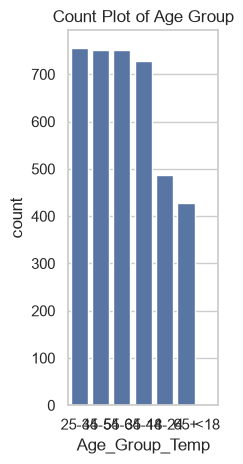

In [42]:
# Subplot 3: Count Plot of Age Group (Using temporary cut on df)
age_bins = [0, 18, 25, 35, 45, 55, 65, 100]
age_labels = ['<18', '18-24', '25-34', '35-44', '45-54', '55-64', '65+']
df['Age_Group_Temp'] = pd.cut(df['Age'], bins=age_bins, labels=age_labels, right=False)
plt.subplot(1, 3, 3)
sns.countplot(x=df['Age_Group_Temp'], order=df['Age_Group_Temp'].value_counts().index)
plt.title('Count Plot of Age Group')
df.drop('Age_Group_Temp', axis=1, inplace=True) # Drop temp column

plt.tight_layout()
plt.show()

--- MULTIVARIATE ANALYSIS (BAR CHARTS) ---

In [44]:
print("\n--- 5. Distribution of Key Categorical Variables ---")
columns_to_plot = [
    'Category', 'Season', 'Gender', 'Size',
    'Payment Method', 'Frequency of Purchases'
]


--- 5. Distribution of Key Categorical Variables ---


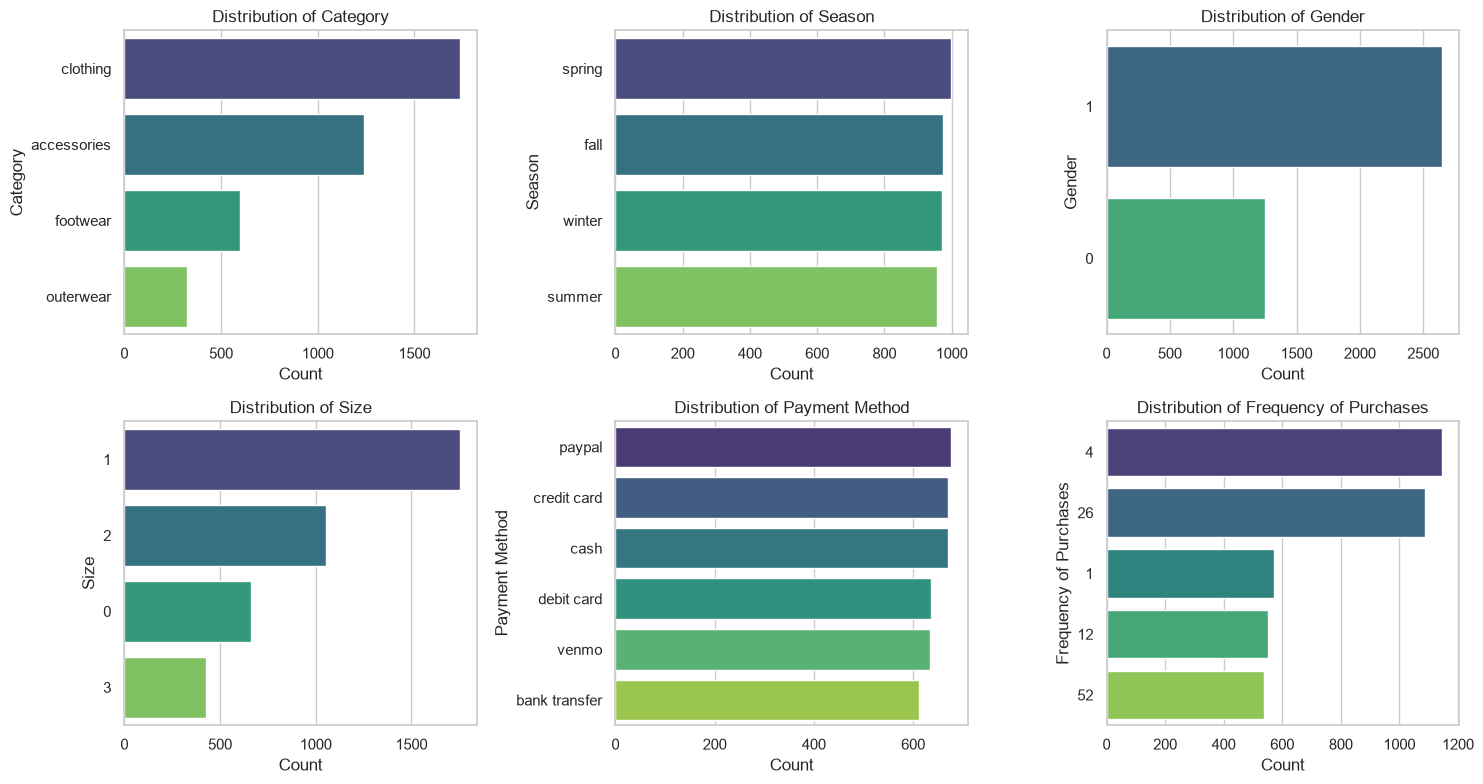

In [45]:
# Create a figure to hold all count plots
n_cols = 3
n_rows = int(np.ceil(len(columns_to_plot) / n_cols))
plt.figure(figsize=(15, 4 * n_rows)) 

for i, col in enumerate(columns_to_plot):
    plt.subplot(n_rows, n_cols, i + 1)
    # Use df for plotting as it contains original categorical values
    sns.countplot(y=df[col], order=df[col].value_counts().index, palette='viridis')
    plt.title(f'Distribution of {col}', fontsize=12)
    plt.xlabel('Count')
    plt.ylabel(col)

plt.tight_layout()
plt.show()

 --- CORRELATION MATRIX (using df_encoded) ---


--- 6. Correlation Matrix of Numerical Features (from df_encoded) ---


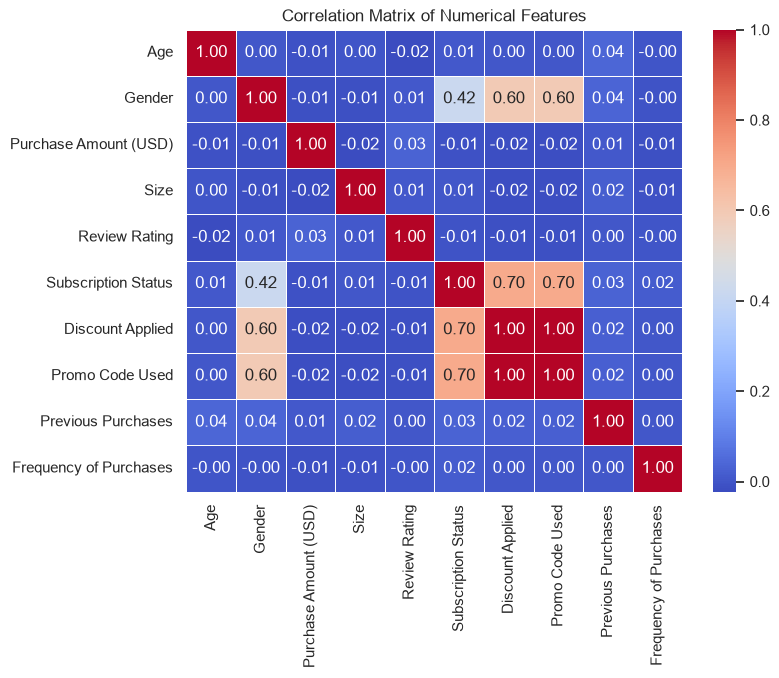

Interpretation: Low correlation values indicate weak linear relationships between the raw numerical features.


In [46]:

print("\n--- 6. Correlation Matrix of Numerical Features (from df_encoded) ---")
numerical_cols = df.select_dtypes(include=['number']).columns 
correlation_matrix = df[numerical_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Correlation Matrix of Numerical Features')
plt.show()
print("Interpretation: Low correlation values indicate weak linear relationships between the raw numerical features.")

--- SEGMENTED DISTRIBUTIONS ---

In [47]:
print("\n--- 7. Segmented Distributions ---")
plt.figure(figsize=(16, 6))


--- 7. Segmented Distributions ---


<Figure size 1600x600 with 0 Axes>

<Figure size 1600x600 with 0 Axes>

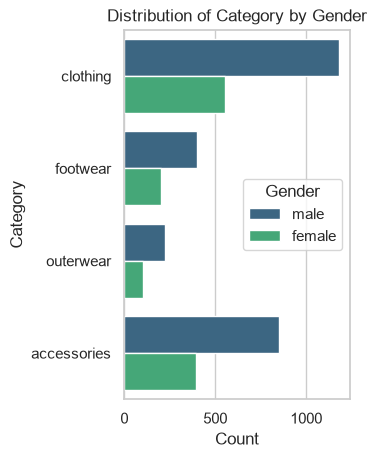

In [48]:
# Subplot 1: Distribution of Category by Gender
plt.subplot(1, 2, 1)
sns.countplot(y=df['Category'], hue=df['Gender'].map({1: 'male', 0: 'female'}), palette='viridis')
plt.title('Distribution of Category by Gender')
plt.xlabel('Count')
plt.ylabel('Category')
plt.legend(title='Gender')

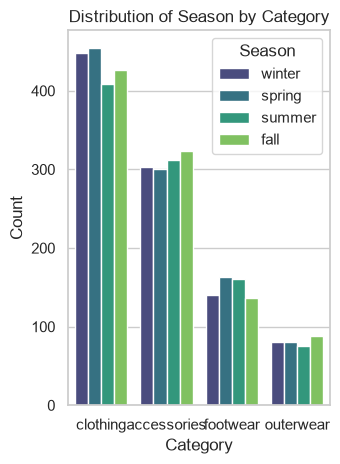

In [49]:
# Subplot 2: Distribution Plot of Season by Category
plt.subplot(1, 2, 2)
sns.countplot(x=df['Category'], hue=df['Season'], palette='viridis', order=df['Category'].value_counts().index)
plt.title('Distribution of Season by Category')
plt.xlabel('Category')
plt.ylabel('Count')
plt.legend(title='Season')

plt.tight_layout()
plt.show()

 --- PURCHASE AMOUNT COMPARISONS ---


In [50]:
print("\n--- 8. Purchase Amount Comparisons ---")
plt.figure(figsize=(16, 6))


--- 8. Purchase Amount Comparisons ---


<Figure size 1600x600 with 0 Axes>

<Figure size 1600x600 with 0 Axes>

Text(0, 0.5, 'Purchase Amount (USD)')

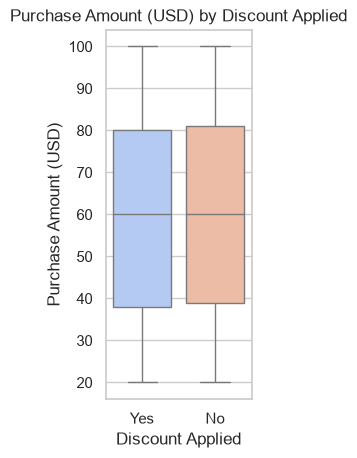

In [51]:
# Subplot 1: Purchase Amount by Discount/Promo Code (Requires encoded columns from df_encoded)
plt.subplot(1, 3, 1)
sns.boxplot(x=df['Discount Applied'].map({1: 'Yes', 0: 'No'}), y=df['Purchase Amount (USD)'], palette='coolwarm')
plt.title('Purchase Amount (USD) by Discount Applied')
plt.xlabel('Discount Applied')
plt.ylabel('Purchase Amount (USD)')

Text(0, 0.5, 'Purchase Amount (USD)')

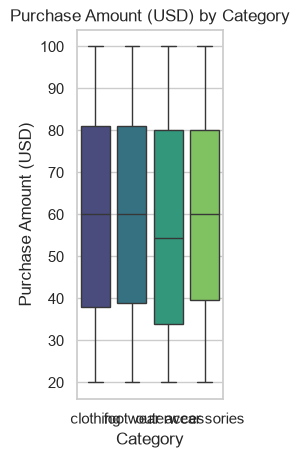

In [52]:
# Subplot 2: Purchase Amount by Category
plt.subplot(1, 3, 2)
sns.boxplot(x='Category', y='Purchase Amount (USD)', data=df, palette='viridis')
plt.title('Purchase Amount (USD) by Category')
plt.xlabel('Category')
plt.ylabel('Purchase Amount (USD)')

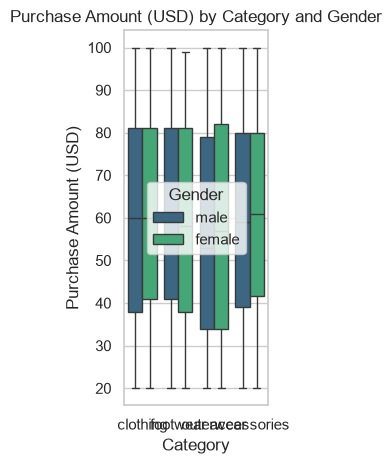


EDA and Data Inspection consolidation complete.


In [53]:
# Subplot 3: Purchase Amount (USD) Segmented by Gender and Category
plt.subplot(1, 3, 3)
sns.boxplot(x=df['Category'], y=df['Purchase Amount (USD)'], hue=df['Gender'].map({1: 'male', 0: 'female'}), palette='viridis')
plt.title('Purchase Amount (USD) by Category and Gender')
plt.xlabel('Category')
plt.ylabel('Purchase Amount (USD)')
plt.legend(title='Gender')

plt.tight_layout()
plt.show()

print("\nEDA and Data Inspection consolidation complete.")

https://www.kaggle.com/code/mounikakalamraju/shopping-behavior-data-analysis

In [54]:
print("Special thanks to Mounika Kalamraju for providing this dataset!")

Special thanks to Mounika Kalamraju for providing this dataset!


In [55]:
print("Dataset & base pipeline inspired by Mounika Kalamraju / Kaggle.")

Dataset & base pipeline inspired by Mounika Kalamraju / Kaggle.
